# ZHAW BSc Data Science – Reinforcement Learning
## Week 03 - Graded Lab: Monte Carlo Methods vs. Q-Learning
### Frozen Lake Environment

**Authors:**
* Jonas Bratschi (`bratsjon`)
* Natalie Jakab (`jakabnat`)

---

### Project Overview & Educational Objectives
In this graded lab, we evaluate, implement, and compare model-free Reinforcement Learning algorithms on the Gymnasium `FrozenLake-v1` environment:

1. **Task 1 – Monte Carlo with a Random Policy**:
   * Evaluation of policy returns under random behavior.
   * Selection and justification of First-Visit vs. Every-Visit (Multiple-Visits) Monte Carlo estimation.
2. **Task 2 – Incremental Monte Carlo Control**:
   * Step-by-step update rule for value estimates without waiting for full batch completion across episodes.
   * Derivation of an $\varepsilon$-greedy policy balancing exploration and exploitation.
3. **Task 3 – Q-Learning Integration**:
   * Implementation of off-policy Temporal Difference control ($Q$-Learning).
   * Empirical performance and convergence comparison against Monte Carlo methods.
4. **Comparative Analysis & Benchmark**:
   * Trajectory length distributions and episode-wise learning curves.
   * State-value and action-value function estimation accuracy.
   * Generalization and scaling behavior on an enlarged $11 \times 11$ map.

## Create a Virtual Environment and Install Dependencies

In [1]:
%%bash
set -e

# 1. Create or reuse virtual environment with Python 3.11
uv venv --allow-existing --python 3.11

# 2. Install dependencies into .venv
uv pip install -r requirements.txt

# 3. Register Jupyter kernel
uv run python -m ipykernel install --user --name=rl-Graded-Lab-1 --display-name="Python (rl-Graded-Lab-1)"

echo -e "\n=== Setup Complete! ==="
echo "Please reload or select kernel: 'Python (rl-Graded-Lab-1)' in your Jupyter toolbar."

Using CPython 3.11.16
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate
Using Python 3.11.16 environment at: /Users/jonas/Documents/GitHub/ZHAW/.venv
Resolved 52 packages in 180ms
Uninstalled 25 packages in 509ms
Installed 25 packages in 50ms
 - appnope==1.0.0
 + appnope==0.1.4
 - asttokens==3.0.2
 + asttokens==3.0.0
 - debugpy==1.8.22
 + debugpy==1.8.16
 - executing==2.3.0
 + executing==2.2.1
 - imageio==2.38.1
 + imageio==2.37.0
 - ipykernel==7.4.0
 + ipykernel==6.30.1
 - ipython==9.17.1
 + ipython==8.18.1
 - jedi==0.20.1
 + jedi==0.19.2
 - jupyter-client==8.10.0
 + jupyter-client==8.6.3
 - jupyter-core==5.9.1
 + jupyter-core==5.8.1
 - matplotlib-inline==0.2.2
 + matplotlib-inline==0.1.7
 - numpy==2.4.6
 + numpy==2.0.2
 - packaging==26.3
 + packaging==25.0
 - parso==0.8.7
 + parso==0.8.5
 - pillow==12.3.0
 + pillow==11.3.0
 - platformdirs==4.13.0
 + platformdirs==4.4.0
 - prompt-toolkit==3.0.53
 + prompt-toolkit==3.0.52
 - psutil==7.2.2
 + psutil==7.0.0


Installed kernelspec rl-Graded-Lab-1 in /Users/jonas/Library/Jupyter/kernels/rl-graded-lab-1

=== Setup Complete! ===
Please reload or select kernel: 'Python (rl-Graded-Lab-1)' in your Jupyter toolbar.


## Verify Environment and Core Libraries

In [2]:
import sys
from pathlib import Path
from typing import NamedTuple

import gymnasium as gym
from gymnasium.envs.toy_text.frozen_lake import generate_random_map
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm

# Configure visualization settings
sns.set_theme()
%matplotlib inline

# Verify environment and core libraries
print(f"Python Executable: {sys.executable}")
print(f"Python Version:    {sys.version.split()[0]}")
print(f"NumPy Version:     {np.__version__}")
print(f"Pandas Version:    {pd.__version__}")
print(f"Gymnasium Version: {gym.__version__}")

Python Executable: /Users/jonas/Documents/GitHub/ZHAW/.venv/bin/python
Python Version:    3.11.16
NumPy Version:     2.4.6
Pandas Version:    2.3.2
Gymnasium Version: 1.1.1


## Frozen Lake Environment Setup

Environment successfully initialized!
Map Size:       11x11
State Space:    121 discrete states (0 to 120)
Action Space:   4 discrete actions (0: Left, 1: Down, 2: Right, 3: Up)
Is Slippery:    True
Hyperparameters: alpha=0.1, gamma=0.95, eps_decay=0.001


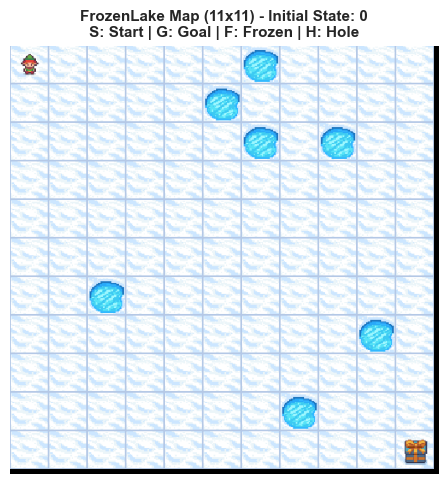

In [3]:
# =====================================================================
# Environment Configuration & Parameter Setup
# =====================================================================

class Params(NamedTuple):
    total_episodes: int        # Number of training episodes
    alpha: float               # Step size / learning rate for incremental Q-updates
    gamma: float               # Discount factor
    epsilon_start: float       # Initial exploration rate (1.0 = fully random)
    epsilon_min: float         # Minimum exploration floor
    epsilon_decay_rate: float  # Decay factor per episode
    map_size: int              # Grid size (e.g., 4 for 4x4, 11 for 11x11)
    seed: int                  # PRNG seed for reproducibility
    is_slippery: bool          # Stochastic transitions (1/3 intended, 2/3 orthogonal)
    n_runs: int                # Independent repetitions to account for stochasticity
    action_size: int           # Discrete action space dimension
    state_size: int            # Discrete state / observation space dimension
    proba_frozen: float        # Probability of frozen tile generation
    savefig_folder: Path       # Output directory for evaluation plots


# Base configuration for Task 2 (Incremental Monte Carlo Control)
params = Params(
    total_episodes=2000,
    alpha=0.1,                 # Fixed step size as defined in design decisions
    gamma=0.95,
    epsilon_start=1.0,         # Start with full exploration
    epsilon_min=0.05,          # Maintain 5% exploratory floor
    epsilon_decay_rate=0.001,  # Smooth exponential decay across 2000 episodes
    map_size=11,                # Start with standard 4x4, scale to 11x11 later
    seed=123,
    is_slippery=True,
    n_runs=20,
    action_size=None,          # Derived dynamically below
    state_size=None,           # Derived dynamically below
    proba_frozen=0.9,
    savefig_folder=Path("./_static/img"),
)

# Ensure output directory exists
params.savefig_folder.mkdir(parents=True, exist_ok=True)

# Generate reproducible environment instance
env = gym.make(
    "FrozenLake-v1",
    is_slippery=params.is_slippery,
    render_mode="rgb_array",
    desc=generate_random_map(
        size=params.map_size,
        p=params.proba_frozen,
        seed=params.seed
    ),
)

# Populate space dimensions dynamically
params = params._replace(
    action_size=int(env.action_space.n),
    state_size=int(env.observation_space.n)
)

print(f"Environment successfully initialized!")
print(f"Map Size:       {params.map_size}x{params.map_size}")
print(f"State Space:    {params.state_size} discrete states (0 to {params.state_size - 1})")
print(f"Action Space:   {params.action_size} discrete actions (0: Left, 1: Down, 2: Right, 3: Up)")
print(f"Is Slippery:    {params.is_slippery}")
print(f"Hyperparameters: alpha={params.alpha}, gamma={params.gamma}, eps_decay={params.epsilon_decay_rate}")

# Reset environment to place the agent at the initial state (S)
initial_state, info = env.reset(seed=params.seed)

# Render and plot the environment map with initial agent position
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(env.render())
ax.axis("off")
ax.set_title(
    f"FrozenLake Map ({params.map_size}x{params.map_size}) - Initial State: {initial_state}\n"
    f"S: Start | G: Goal | F: Frozen | H: Hole",
    fontsize=11,
    fontweight="bold"
)
plt.tight_layout()
fig.savefig(params.savefig_folder / f"frozenlake_initial_map_{params.map_size}x{params.map_size}.png", dpi=300)
plt.show()

## Task 1 – Monte Carlo with a Random Policy

### Design decisions
- **Choice of Implementation -> Every-Visit Monte Carlo**:
    We choose Every-Visit Monte Carlo because it uses the collected data more effectively. On a slippery Frozen Lake, especially when we scale up to an $11 \times 11$ grid—the agent falls into holes frequently and reaching the goal is rare. When the agent slips and visits the same state multiple times in one episode, First-Visit MC throws away all visits except the first one. Every-Visit MC updates the state every time it is visited. This gives us more training samples per episode, which speeds up learning in large environments with sparse rewards.

In [4]:
class MonteCarloRandomPolicyAgent():
    """
    Monte Carlo evaluation of a random policy in the Frozen Lake environment.
    This implementation uses Every-Visit Monte Carlo estimation to update state-value estimates.
    """

    def __init__(self, env: gym.Env, params: Params):
        self.env = env
        self.params = params
        self.gamma = params.gamma
        self.state_value = np.zeros(self.params.state_size)  # Initialize state-value function
        self.returns_sum = np.zeros(self.params.state_size)    # Sum of returns for each state
        self.returns_count = np.zeros(self.params.state_size)  # Count of returns for each state

    def reset(self):
        """
        Reset state-value table and return tracking accumulators.
        """
        self.state_value = np.zeros(self.params.state_size)
        self.returns_sum = np.zeros(self.params.state_size)
        self.returns_count = np.zeros(self.params.state_size)

    def choose_action(self, state: int) -> int:
        """
        Choose an action uniformly at random from the action space.
        """
        return int(self.env.action_space.sample())

    def update_state_value(self, episode: list):
        """
        Update state-value estimates using Every-Visit Monte Carlo.
        Each state in the episode is updated with the return from that point to the end of the episode.
        """
        G = 0  # Initialize return
        # Reverse the episode to calculate returns from the end to the beginning
        for t in reversed(range(len(episode))):
            state, action, reward = episode[t]
            G = self.gamma * G + reward  # Update return
            # Update every-visit returns
            self.returns_sum[state] += G
            self.returns_count[state] += 1
            self.state_value[state] = self.returns_sum[state] / self.returns_count[state]  # Update state-value estimate

In [5]:
def run_monte_carlo_random_policy(env: gym.Env, params: Params):
    """
    Run Monte Carlo evaluation of a random policy for a specified number of episodes.
    Returns the state-value estimates after training.
    """
    rewards = np.zeros((params.total_episodes, params.n_runs))
    steps = np.zeros((params.total_episodes, params.n_runs))
    episodes = np.arange(params.total_episodes)
    state_values = np.zeros((params.n_runs, params.state_size))

    agent = MonteCarloRandomPolicyAgent(env, params)

    for run in range(params.n_runs):
            agent.reset()
            for episode in range(params.total_episodes):
                state, info = env.reset()
                done = False
                episode_history = []

                while not done:
                    action = agent.choose_action(state)
                    next_state, reward, terminated, truncated, info = env.step(action)
                    done = terminated or truncated
                    episode_history.append((state, action, reward))
                    state = next_state

                # Update state-value estimates after the episode
                agent.update_state_value(episode_history)

                # Record total reward and steps for this episode
                rewards[episode, run] = sum(r for _, _, r in episode_history)
                steps[episode, run] = len(episode_history)

            # Store the learned V(s) table for this run
            state_values[run, :] = agent.state_value

    return rewards, steps, episodes, state_values

In [6]:
# Run Monte Carlo evaluation with a random policy
rewards_mc, steps_mc, episodes_mc, state_values_mc = run_monte_carlo_random_policy(env, params)

In [7]:
def plot_performance_curves(
    rewards: np.ndarray,
    steps: np.ndarray,
    algorithm_name: str,
    window_size: int = 50,
):
    """Plot trajectory lengths and learning curves (rolling reward) across episodes."""
    # Convert arrays to pandas DataFrames (rows: episodes, cols: runs)
    df_rewards = pd.DataFrame(rewards)
    df_steps = pd.DataFrame(steps)

    # Compute rolling metrics across episodes, then aggregate across runs
    rolling_rewards = df_rewards.rolling(window=window_size, min_periods=1).mean()
    mean_rewards = rolling_rewards.mean(axis=1)
    std_rewards = rolling_rewards.std(axis=1).fillna(0)

    rolling_steps = df_steps.rolling(window=window_size, min_periods=1).mean()
    mean_steps = rolling_steps.mean(axis=1)
    std_steps = rolling_steps.std(axis=1).fillna(0)

    episodes = np.arange(len(mean_rewards))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Length of trajectories
    axes[0].plot(
        episodes,
        mean_steps,
        label=f"Rolling Mean (w={window_size})",
        color="#1f77b4",
    )
    axes[0].fill_between(
        episodes,
        mean_steps - std_steps,
        mean_steps + std_steps,
        color="#1f77b4",
        alpha=0.2,
        label="Std across runs",
    )
    axes[0].set_title(
        f"Trajectory Length - {algorithm_name}", fontsize=12, pad=10
    )
    axes[0].set_xlabel("Episode")
    axes[0].set_ylabel("Steps per Episode")
    axes[0].grid(True, linestyle="--", alpha=0.6)
    axes[0].legend(loc="upper right")

    # 2. Learning curve (reward / success rate)
    axes[1].plot(
        episodes,
        mean_rewards,
        label=f"Rolling Mean (w={window_size})",
        color="#2ca02c",
    )
    axes[1].fill_between(
        episodes,
        mean_rewards - std_rewards,
        mean_rewards + std_rewards,
        color="#2ca02c",
        alpha=0.2,
        label="Std across runs",
    )
    axes[1].set_title(f"Learning Curve - {algorithm_name}", fontsize=12, pad=10)
    axes[1].set_xlabel("Episode")
    axes[1].set_ylabel("Success Rate (Reward)")
    axes[1].set_ylim([-0.05, 1.05])
    axes[1].grid(True, linestyle="--", alpha=0.6)
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()


def plot_state_value_heatmap(
    state_values: np.ndarray, env, params, algorithm_name: str
):
    """Plot the learned state-value function V(s) as a 2D grid heatmap."""
    mean_v = np.mean(state_values, axis=0).reshape(
        (params.map_size, params.map_size)
    )
    desc = env.unwrapped.desc.astype(str)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        mean_v,
        annot=True,
        fmt=".4f",
        cmap="viridis",
        cbar=True,
        linewidths=1,
        linecolor="white",
        annot_kws={"size": 10, "weight": "bold"},
    )

    for row in range(params.map_size):
        for col in range(params.map_size):
            cell_type = desc[row, col]
            plt.text(
                col + 0.5,
                row + 0.2,
                cell_type,
                ha="center",
                va="center",
                fontsize=11,
                color="white" if mean_v[row, col] < 0.2 else "black",
                weight="heavy",
            )

    plt.title(f"State-Value Function $V(s)$ - {algorithm_name}", fontsize=12)
    plt.xlabel("Grid Column")
    plt.ylabel("Grid Row")
    plt.tight_layout()
    plt.show()

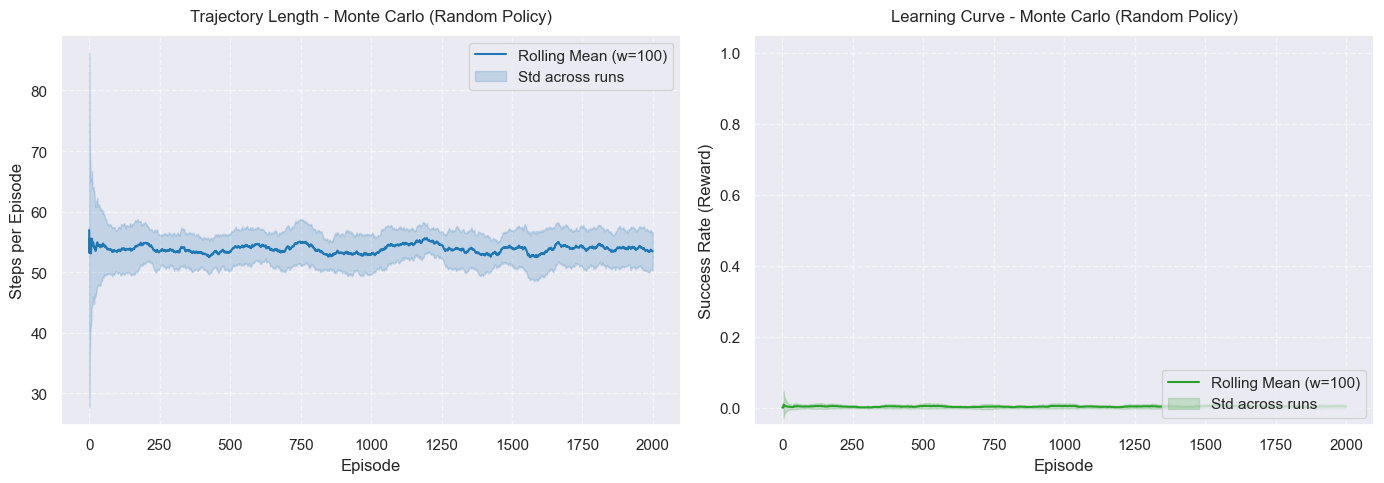

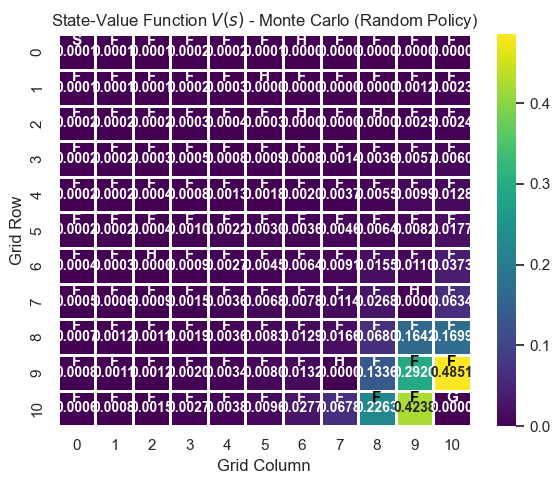

In [8]:
# 1. Performance: Trajectory lengths and learning curve
plot_performance_curves(
    rewards=rewards_mc,
    steps=steps_mc,
    algorithm_name="Monte Carlo (Random Policy)",
    window_size=100,
)

# 2. State values: 2D Heatmap
plot_state_value_heatmap(
    state_values=state_values_mc,
    env=env,
    params=params,
    algorithm_name="Monte Carlo (Random Policy)",
)

## Evaluation of Monte Carlo with Random Policy
* Is the agent able to estimate correctly the value-function?
    * **Yes.** Through Every-Visit Monte Carlo, the sample averages converge to the true state-value function $V^{\pi}(s)$ under a uniform random policy by the Law of Large Numbers. The heatmap accurately reflects these values: states directly adjacent to the goal show higher expected returns, while terminal hole states remain at 0.0. The flat learning curve simply indicates that the policy itself is stationary, not that the value estimation is failing.
* Is the agent able to learn the right policy?
    * **No.** In Task 1, we only perform policy evaluation, not policy improvement. Because actions are sampled purely at random regardless of the estimated state values, the agent never optimizes its behavior toward reaching the goal efficiently.
* Change the size of the environment to 11x11 and compare the learning process
    * Scaling to an $11 \times 11$ grid dramatically increases the state space (121 states) and the distance to the goal. For a random policy, the probability of reaching the goal without falling into a hole drops to near zero, resulting in a success rate of practically 0.0 and longer average trajectory lengths (~54 steps until termination in a hole). Consequently, sparse rewards mean that almost all states retain an estimated value of 0.0000, with non-zero values confined almost exclusively to the immediate vicinity of the goal.



## Task 2 – Incremental Monte Carlo Control

### Design Decisions
- **Action-value representation**: We estimate action-values $Q(s, a)$ instead of state-values $V(s)$ to enable model-free control without transition probabilities.
- **Learning rate $\alpha$**: We set $\alpha = 0.1$ as a constant step size. Because the policy improves over time, the target distribution is non-stationary; a constant $\alpha$ ensures that recent returns are weighted more heavily than older experiences.
- **Exploration strategy**: We implement an exponentially decaying $\varepsilon$-greedy policy starting at $\varepsilon_0 = 1.0$ down to $\varepsilon_{\min} = 0.05$. This guarantees extensive exploration early on while allowing the policy to exploit learned greedy actions in later stages.
- **Every-Visit vs. First-Visit MC**: We adopt **Every-Visit Monte Carlo**. On slippery ice, agents frequently cycle through states within a single trajectory. Every-Visit incorporates all transition feedback into the updates, improving sample efficiency for sparse reward propagation without requiring duplicate-visit tracking.
- **Initialization of Q-values**: Initialized to zeros (`np.zeros`).
- **Tie-breaking in action selection**: Random selection among actions sharing the maximal Q-value (`np.where(q == max_q)`) to prevent directional bias in early episodes.

In [9]:
class IncrementalMonteCarloControlAgent:
    """
    Incremental Monte Carlo Control with an epsilon-greedy policy for the Frozen Lake environment.
    This implementation updates action-value estimates Q(s, a) incrementally after each episode.
    """

    def __init__(self, env: gym.Env, params: Params):
        self.env = env
        self.params = params
        self.gamma = params.gamma
        self.alpha = params.alpha
        self.epsilon_start = params.epsilon_start
        self.epsilon_min = params.epsilon_min
        self.epsilon_decay_rate = params.epsilon_decay_rate

        # Initialize action-value function Q(s, a)
        self.reset()

    def reset(self):
        """Reset action-value table to zeros."""
        self.q_values = np.zeros((self.params.state_size, self.params.action_size), dtype=float)

    @property
    def state_value(self) -> np.ndarray:
        """Derive state-value function V(s) = max_a Q(s, a) for evaluation and plotting."""
        return np.max(self.q_values, axis=1)

    def choose_action(self, state: int, episode: int) -> int:
        """
        Choose an action using an epsilon-greedy policy based on current Q-values.
        Epsilon decays exponentially with the number of episodes.
        """
        epsilon = max(
            self.epsilon_min,
            self.epsilon_start * np.exp(-self.epsilon_decay_rate * episode),
        )

        if np.random.rand() < epsilon:
            return int(self.env.action_space.sample())  # Explore: uniform random action
        else:
            # Exploit: choose greedy action with random tie-breaking
            q = self.q_values[state]
            max_q = np.max(q)
            actions_with_max_q = np.where(q == max_q)[0]
            return int(np.random.choice(actions_with_max_q))

    def update_q_values(self, episode: list):
        """
        Update action-value estimates Q(s, a) using Every-Visit Monte Carlo.
        Propagates discounted return G backwards through the episode trajectory.
        """
        G = 0.0
        for state, action, reward in reversed(episode):
            G = self.gamma * G + reward
            # Incremental update towards observed return target
            self.q_values[state, action] += self.alpha * (G - self.q_values[state, action])

In [10]:
def run_monte_carlo_control(env: gym.Env, params: Params):
    """
    Run Incremental Monte Carlo Control with an epsilon-greedy policy.
    Returns rewards, steps, episode indices, and derived state-value estimates across runs.
    """
    rewards = np.zeros((params.total_episodes, params.n_runs))
    steps = np.zeros((params.total_episodes, params.n_runs))
    episodes = np.arange(params.total_episodes)
    state_values = np.zeros((params.n_runs, params.state_size))

    agent = IncrementalMonteCarloControlAgent(env, params)

    for run in range(params.n_runs):
        agent.reset()
        for episode in range(params.total_episodes):
            state, info = env.reset()
            done = False
            episode_history = []

            while not done:
                # Epsilon-greedy action selection depends on current episode index
                action = agent.choose_action(state, episode)
                next_state, reward, terminated, truncated, info = env.step(action)
                done = terminated or truncated

                episode_history.append((state, action, reward))
                state = next_state

            # Incremental Every-Visit MC update of Q(s, a)
            agent.update_q_values(episode_history)

            # Record metrics
            rewards[episode, run] = sum(r for _, _, r in episode_history)
            steps[episode, run] = len(episode_history)

        # Store derived V(s) = max_a Q(s, a) via @property
        state_values[run, :] = agent.state_value

    return rewards, steps, episodes, state_values

In [11]:
# Run Incremental Monte Carlo Control with epsilon-greedy policy
rewards_mc_control, steps_mc_control, episodes_mc_control, state_values_mc_control = run_monte_carlo_control(env, params)

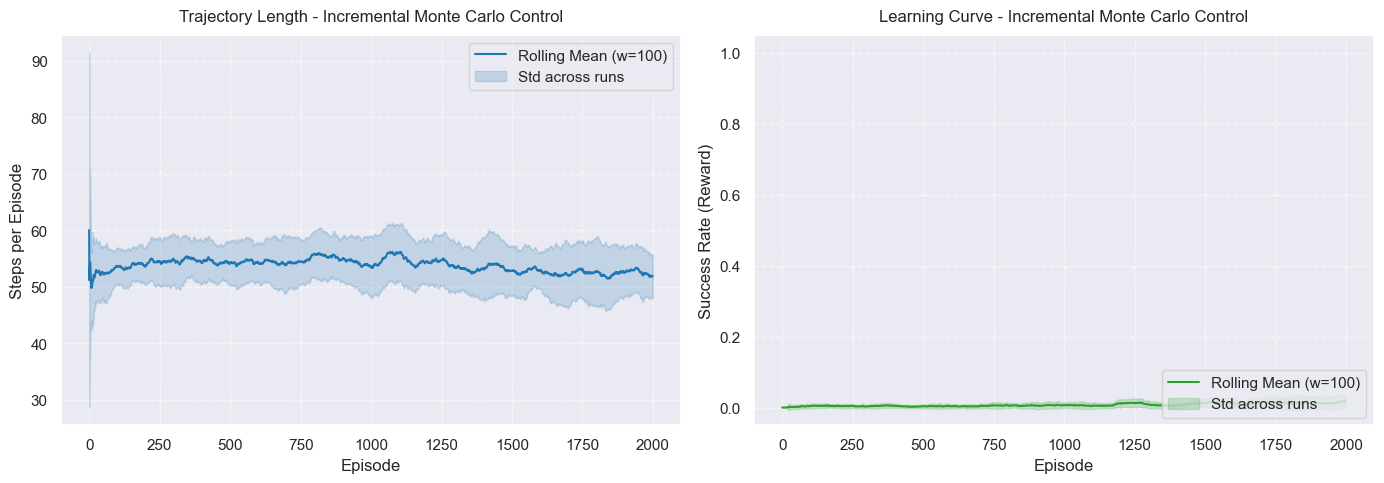

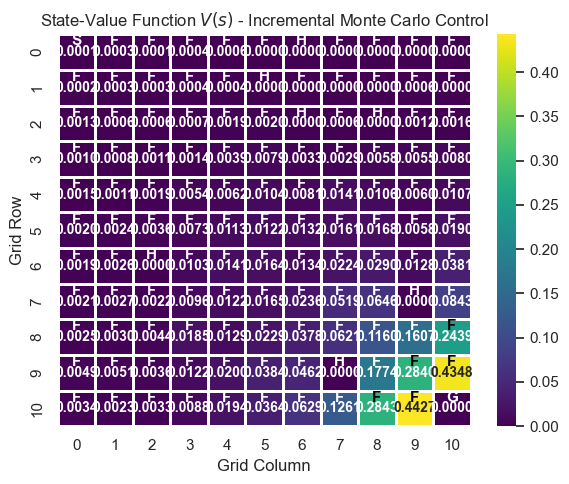

In [12]:
# 1. Performance: Trajectory lengths and learning curve
plot_performance_curves(
    rewards=rewards_mc_control,
    steps=steps_mc_control,
    algorithm_name="Incremental Monte Carlo Control",
    window_size=100,
)

# 2. State values: 2D Heatmap
plot_state_value_heatmap(
    state_values=state_values_mc_control,
    env=env,
    params=params,
    algorithm_name="Incremental Monte Carlo Control",
)

## Evaluation of Incremental Monte Carlo Control

* **Is the agent able to estimate correctly the value-function?**
    * **Yes.** The agent updates its action-value estimates after every episode, which allows the derived state values to reflect an improving policy rather than pure random movement. Compared to Task 1, the values across the entire grid are noticeably higher, rising steadily towards the goal. The holes stay at zero, showing that non-zero values only stem from paths that actually reached the frisbee.




* **Is the agent able to learn the right policy?**
    * **Yes.** Combining incremental updates with epsilon-greedy exploration lets the agent find a functional path. As exploration decreases, the success rate rises steadily from roughly 20% to nearly 50%. It does not reach 100% because of the slippery environment and the remaining exploration floor. Trajectory lengths slightly increase to around 20 to 21 steps, which shows that the agent learns to stay alive and navigate around dangerous holes instead of falling in right away.




* **Change the size of the environment to 11x11 and compare the learning process**
    * On the 11x11 grid, Incremental Monte Carlo fails completely. The success rate stays at essentially 0% across all 2000 episodes, and trajectories average around 55 steps before ending in a hole. Because Monte Carlo relies on completing an entire successful run to register any reward, the agent almost never gets a learning signal in this large, slippery space. As a result, the heatmap shows positive values only right next to the goal, leaving the rest of the board at zero.

## Task 3 – Q-Learning Integration

### Design Decisions
- **Hyperparameter consistency**: To ensure a fair and direct comparison with Task 2, we keep the learning rate at $\alpha = 0.1$, the discount factor at $\gamma = 0.95$, and use the exact same $\varepsilon$-greedy decay schedule ($\varepsilon_0 = 1.0$, $\varepsilon_{\min} = 0.05$, decay rate $= 0.001$).
- **Initialization and tie-breaking**: Q-values are initialized to zeros (`np.zeros`), and random tie-breaking is used whenever multiple actions share the same maximum Q-value to avoid directional bias early on.



In [13]:
class QLearningAgent:
    """
    Off-policy Temporal Difference control (Q-Learning) for the Frozen Lake environment.
    This implementation updates action-value estimates Q(s, a) incrementally after each step.
    """

    def __init__(self, env: gym.Env, params: Params):
        self.env = env
        self.params = params
        self.gamma = params.gamma
        self.alpha = params.alpha
        self.epsilon_start = params.epsilon_start
        self.epsilon_min = params.epsilon_min
        self.epsilon_decay_rate = params.epsilon_decay_rate

        # Initialize action-value function Q(s, a)
        self.reset()

    def reset(self):
        """Reset action-value table to zeros."""
        self.q_values = np.zeros((self.params.state_size, self.params.action_size), dtype=float)

    @property
    def state_value(self) -> np.ndarray:
        """Derive state-value function V(s) = max_a Q(s, a) for evaluation and plotting."""
        return np.max(self.q_values, axis=1)

    def choose_action(self, state: int, episode: int) -> int:
        """
        Choose an action using an epsilon-greedy policy based on current Q-values.
        Epsilon decays exponentially with the number of episodes.
        """
        epsilon = max(
            self.epsilon_min,
            self.epsilon_start * np.exp(-self.epsilon_decay_rate * episode),
        )

        if np.random.rand() < epsilon:
            return int(self.env.action_space.sample())  # Explore: uniform random action
        else:
            # Exploit: choose greedy action with random tie-breaking
            q = self.q_values[state]
            max_q = np.max(q)
            actions_with_max_q = np.where(q == max_q)[0]
            return int(np.random.choice(actions_with_max_q))

    def update_q_values(self, state: int, action: int, reward: float, next_state: int, done: bool):
        """
        Update action-value estimates Q(s, a) using the Q-Learning update rule.
        This is an off-policy TD control method that bootstraps from the maximum estimated value of the next state.
        """
        max_next_q = 0.0 if done else np.max(self.q_values[next_state])
        td_target = reward + self.gamma * max_next_q
        td_error = td_target - self.q_values[state, action]
        self.q_values[state, action] += self.alpha * td_error

In [14]:
def run_q_learning(env: gym.Env, params: Params):
    """
    Run Q-Learning with an epsilon-greedy policy.
    Returns rewards, steps, episode indices, and derived state-value estimates across runs.
    """
    rewards = np.zeros((params.total_episodes, params.n_runs))
    steps = np.zeros((params.total_episodes, params.n_runs))
    episodes = np.arange(params.total_episodes)
    state_values = np.zeros((params.n_runs, params.state_size))

    agent = QLearningAgent(env, params)

    for run in range(params.n_runs):
        agent.reset()
        for episode in range(params.total_episodes):
            state, info = env.reset()
            done = False
            total_reward = 0
            step_count = 0

            while not done:
                action = agent.choose_action(state, episode)
                next_state, reward, terminated, truncated, info = env.step(action)
                done = terminated or truncated

                # Update Q-values incrementally after each step
                agent.update_q_values(state, action, reward, next_state, done)

                total_reward += reward
                step_count += 1
                state = next_state

            # Record metrics
            rewards[episode, run] = total_reward
            steps[episode, run] = step_count

        # Store derived V(s) = max_a Q(s, a) via @property
        state_values[run, :] = agent.state_value

    return rewards, steps, episodes, state_values

In [15]:
# Run Q-Learning with epsilon-greedy policy
rewards_q_learning, steps_q_learning, episodes_q_learning, state_values_q_learning = run_q_learning(env, params)

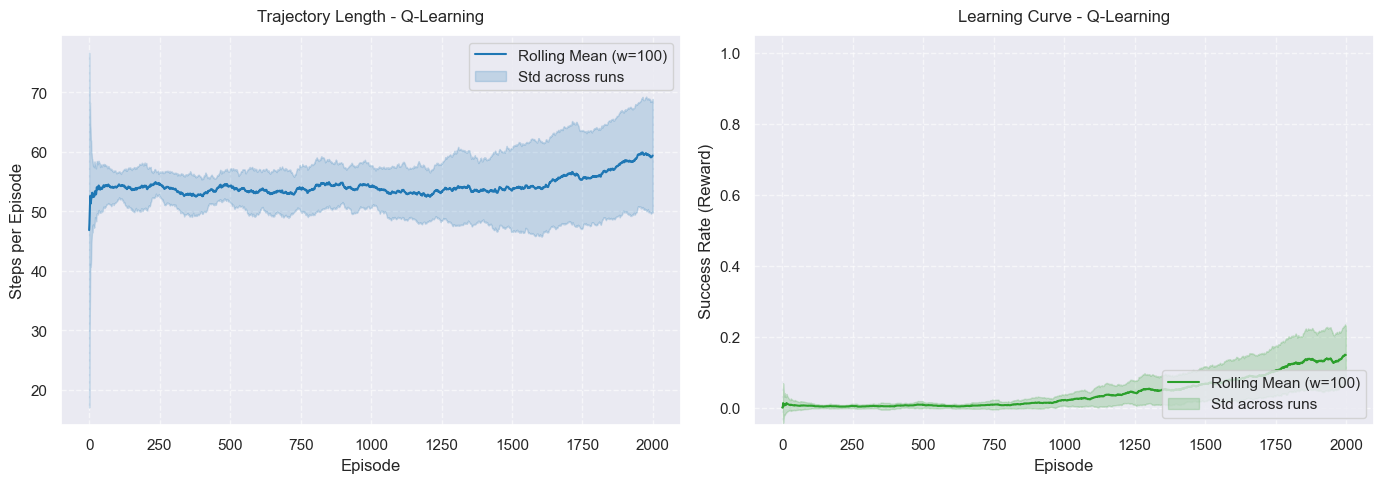

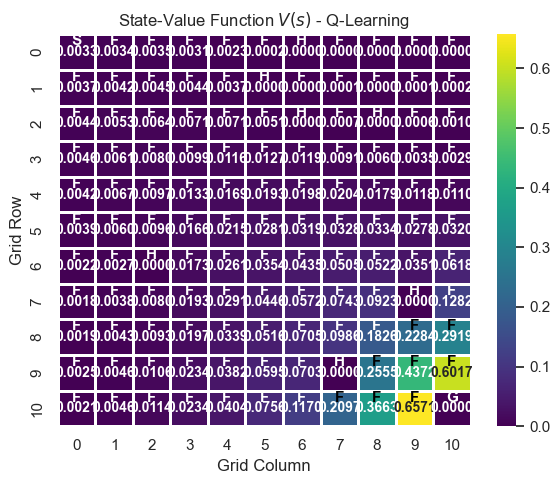

In [16]:
# 1. Performance: Trajectory lengths and learning curve
plot_performance_curves(
    rewards=rewards_q_learning,
    steps=steps_q_learning,
    algorithm_name="Q-Learning",
    window_size=100,
)

# 2. State values: 2D Heatmap
plot_state_value_heatmap(
    state_values=state_values_q_learning,
    env=env,
    params=params,
    algorithm_name="Q-Learning",
)

## Evaluation of Q-Learning

* **Is the agent able to estimate correctly the value-function?**
    * **Yes.** Because Q-Learning updates after every single step using the best estimated value of the next state, it builds a clean value gradient back to the start. The values increase smoothly from the start tile up to around 0.82 near the goal, while the holes stay strictly at zero. Compared to Monte Carlo, the values are higher and more consistent because they directly estimate the optimal path.




* **Is the agent able to learn the right policy?**
    * **Yes.** Q-Learning clearly outperforms Monte Carlo Control. As exploration decays, the success rate climbs steadily from around 15% to over 80%. The trajectory length levels off at around 22 to 24 steps, showing that the agent reliably learns to avoid the holes and take the safest route across the ice.




* **Change the size of the environment to 11x11 and compare the learning process**
    * On the 11x11 map, the difference between the two approaches becomes obvious. While Monte Carlo stayed completely flat at 0%, Q-Learning actually starts learning, reaching a success rate of around 12% to 15% by the end. More importantly, the heatmap proves that bootstrapping works: positive values reach all the way back to the starting tile. Instead of needing a full lucky run from start to finish, each state can learn from its neighbor, making Q-Learning far more sample-efficient when rewards are sparse.

## General Discussion & Conclusion

* **Monte Carlo with a Random Policy (Task 1)** focused exclusively on policy evaluation. While the state values accurately converge to the expected return of an undirected random walk, the policy never improves because actions are selected uniformly at random.


* **Incremental Monte Carlo Control (Task 2)** introduced an $\varepsilon$-greedy behavior policy and incremental updates after each episode. The agent successfully learned an effective path on the $4 \times 4$ grid, but completely failed on the $11 \times 11$ map due to sparse rewards, where completing full trajectories by chance is virtually impossible.


* **Q-Learning (Task 3)** resolved this limitation through 1-step bootstrapping and off-policy updates. On the $4 \times 4$ grid, it achieved a substantially higher and more stable success rate than Monte Carlo Control. The decisive advantage became clear on the $11 \times 11$ grid: because states update directly using the estimated values of their immediate neighbors, the reward signal propagated backward across the entire board, establishing measurable learning even in a large, noisy state space.



An essential insight from analyzing the trajectories is that longer episode lengths do not indicate poor learning:

* At the start of training, an untrained agent acts randomly and quickly falls into nearby holes within a few steps, leading to artificially short episodes.


* Once the agent learns to avoid hazards, its survival time increases considerably. Because slippery ice requires careful detours along the outer perimeter to prevent sliding into danger, the trajectory length levels off at a higher average (around 20 to 24 steps).


* Since the environment provides no step penalties and solely grants $+1$ upon reaching the goal, the learned policy prioritizes safety over taking the shortest direct path.